* import the dataset

In [2]:
import pandas as pd
import numpy as np 
df = pd.read_csv('heart.csv')
df.head(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
5,57,1,0,140,192,0,1,148,0,0.4,1,0,1,1
6,56,0,1,140,294,0,0,153,0,1.3,1,0,2,1
7,44,1,1,120,263,0,1,173,0,0.0,2,0,3,1
8,52,1,2,172,199,1,1,162,0,0.5,2,0,3,1
9,57,1,2,150,168,0,1,174,0,1.6,2,0,2,1


* cleaning the datasset

In [3]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [4]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (302, 14)


In [5]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,302.00000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000
mean,54.42053,0.682119,0.963576,131.602649,246.500000,0.149007,0.526490,149.569536,0.327815,1.043046,1.397351,0.718543,2.314570,0.543046
std,9.04797,0.466426,1.032044,17.563394,51.753489,0.356686,0.526027,22.903527,0.470196,1.161452,0.616274,1.006748,0.613026,0.498970
min,29.00000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.00000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.250000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.50000,1.000000,1.000000,130.000000,240.500000,0.000000,1.000000,152.500000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.00000,1.000000,2.000000,140.000000,274.750000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.00000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [6]:
print(df["target"].value_counts())

target
1    164
0    138
Name: count, dtype: int64


In [8]:
X = df.drop("target", axis=1) # X = patient information
y = df["target"] #y = heart disease result

In [9]:
print("Features:", X.columns.tolist())
print("Target:", y.name)

Features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Target: target


* train test split 

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (211, 13)
Testing data: (91, 13)


In [18]:
print(df.isnull().sum())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train shape:", X_train_scaled.shape)
print("X_test shape:", X_test_scaled.shape)

X_train shape: (211, 13)
X_test shape: (91, 13)


In [20]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42)

In [21]:
model.fit(X_train_scaled, y_train)

print("Model training completed.")

Model training completed.


In [22]:
y_pred = model.predict(X_test_scaled)

print("Predictions:")
print(y_pred)


Predictions:
[1 0 0 0 0 0 1 1 1 0 0 1 1 0 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 0 0 1 1 0 1 0 0
 0 1 1 1 1 1 1 1 1 0 0 0 0 1 0 1 1 1 1 0 1 0 1 1 1 1 0 1 0 1 1 0 1 0 1 1 1
 1 0 0 1 0 0 1 0 1 1 1 1 1 1 1 0 0]


In [31]:
import numpy as np

# New unseen patient data
new_patient = np.array([[
    55, 1, 2, 140, 240, 0, 1,
    160, 0, 1.2, 1, 0, 2
]])

# Scale using the SAME scaler used during training
new_patient_scaled = scaler.transform(new_patient)

# Predict
prediction = model.predict(new_patient_scaled)

print("Prediction:", prediction[0])

Prediction: 1


d:\Machine learning\ml\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [33]:
import pandas as pd

new_data = pd.DataFrame({
    "age": [55, 45, 62, 39, 58],
    "sex": [1, 0, 1, 1, 0],
    "cp": [2, 1, 3, 0, 2],
    "trestbps": [140, 130, 150, 120, 135],
    "chol": [240, 210, 280, 190, 250],
    "fbs": [0, 0, 1, 0, 0],
    "restecg": [1, 0, 1, 0, 1],
    "thalach": [160, 172, 145, 185, 150],
    "exang": [0, 0, 1, 0, 1],
    "oldpeak": [1.2, 0.8, 2.5, 0.5, 1.8],
    "slope": [1, 2, 0, 2, 1],
    "ca": [0, 0, 2, 0, 1],
    "thal": [2, 2, 3, 2, 3],
    
    # Actual values for checking accuracy
    "target": [1, 1, 0, 1, 0]
})

new_data.to_csv("new_unseen_data.csv", index=False)

print("New unseen data created successfully!")

New unseen data created successfully!


In [34]:
from sklearn.metrics import accuracy_score

new_data = pd.read_csv("new_unseen_data.csv")

X_new = new_data.drop("target", axis=1)
y_actual = new_data["target"]

# Scale using the same scaler
X_new_scaled = scaler.transform(X_new)

# Predict
y_new_pred = model.predict(X_new_scaled)

print("Actual:", y_actual.values)
print("Predicted:", y_new_pred)

accuracy = accuracy_score(y_actual, y_new_pred)

print("New Unseen Data Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Actual: [1 1 0 1 0]
Predicted: [1 1 0 1 1]
New Unseen Data Accuracy: 0.8
Accuracy Percentage: 80.0 %


In [35]:
y_new_pred = model.predict(X_new_scaled)

In [25]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)


print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7802197802197802

Confusion Matrix:
[[29 13]
 [ 7 42]]


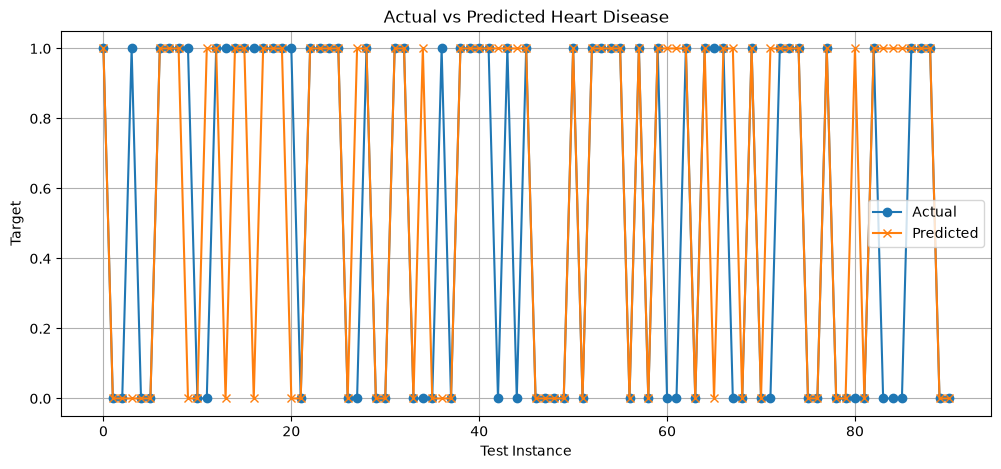

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(y_test.values, label="Actual", marker="o")
plt.plot(y_pred, label="Predicted", marker="x")

plt.xlabel("Test Instance")
plt.ylabel("Target")
plt.title("Actual vs Predicted Heart Disease")
plt.legend()
plt.grid(True)

plt.show()

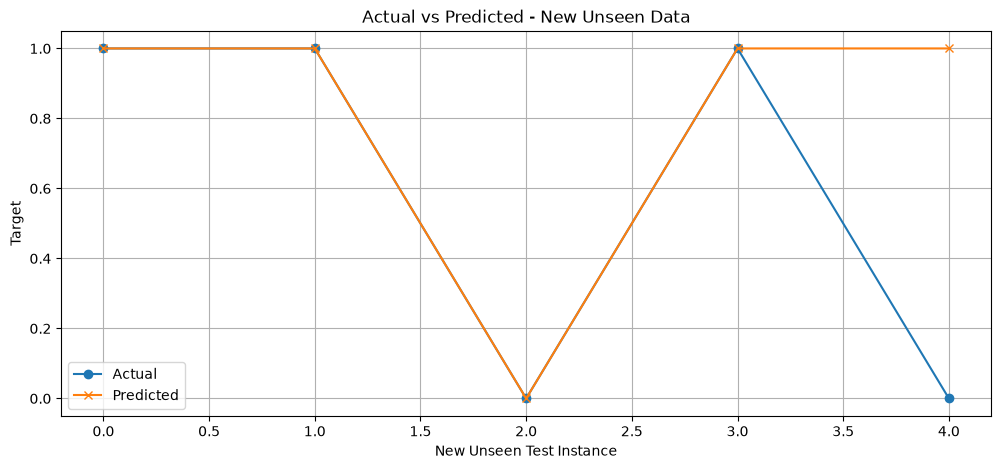

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(y_actual.values, label="Actual", marker="o")
plt.plot(y_new_pred, label="Predicted", marker="x")

plt.xlabel("New Unseen Test Instance")
plt.ylabel("Target")

plt.title("Actual vs Predicted - New Unseen Data")

plt.legend()
plt.grid(True)

plt.show()

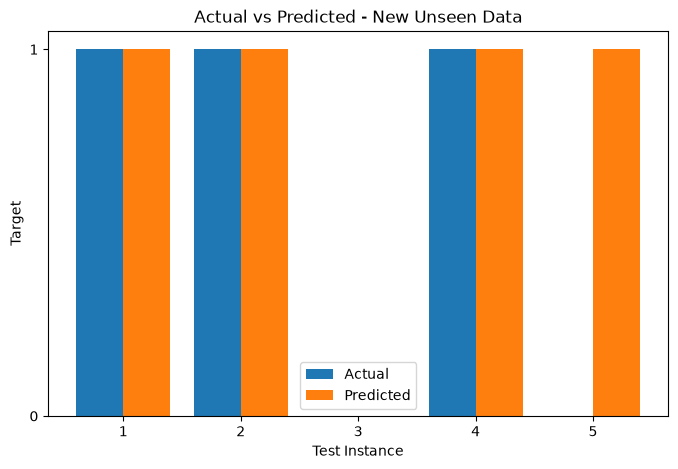

In [37]:
import matplotlib.pyplot as plt
import numpy as np

actual = [1, 1, 0, 1, 0]
predicted = [1, 1, 0, 1, 1]

test_instances = np.arange(1, 6)

plt.figure(figsize=(8, 5))

plt.bar(test_instances - 0.2, actual,
        width=0.4, label="Actual")

plt.bar(test_instances + 0.2, predicted,
        width=0.4, label="Predicted")

plt.xlabel("Test Instance")
plt.ylabel("Target")
plt.title("Actual vs Predicted - New Unseen Data")

plt.xticks(test_instances)
plt.yticks([0, 1])
plt.legend()

plt.show()